# Hotel Booking Cancellation Risk: An End-to-End Boosting Project

**Student name:** Shaurya Sharma 
**Course / batch:** October Batch B 
**Dataset:** Hotel Booking Demand  
**Task:** Binary classification with gradient boosting

This notebook studies which booking characteristics are associated with cancellations and builds a gradient-boosting classifier to flag higher-risk bookings. It includes data checks, cleaning choices, visual exploration, a chronological holdout evaluation, and limitations.


## 1. Problem and objective

Hotel cancellations can leave rooms unsold or force a hotel to adjust its inventory. The project asks:

> Can booking information recorded around reservation time help identify bookings that may later be cancelled?

The target variable is is_canceled (1 = canceled, 0 = not canceled). The main model is a gradient-boosting classifier. A simple majority-class prediction is the baseline. This is an educational historical analysis, not a live hotel decision system.


In [ ]:
%matplotlib inline
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 40)

def find_dataset():
    direct_paths = [
        Path("data/hotel_bookings.csv"),
        Path("hotel_bookings.csv"),
        Path("/kaggle/input/hotel-booking-demand/hotel_bookings.csv"),
    ]
    for candidate in direct_paths:
        if candidate.is_file():
            return candidate
    for root in [Path.cwd(), Path("/kaggle/input")]:
        if root.exists():
            for candidate in root.rglob("hotel_bookings.csv"):
                return candidate
    raise FileNotFoundError(
        "Place hotel_bookings.csv in a data folder, or attach the Hotel Booking Demand "
        "dataset as a Kaggle Notebook input."
    )

dataset_path = find_dataset()
data = pd.read_csv(dataset_path)
print(f"Loaded: {dataset_path}")
print(f"Rows: {len(data):,} | Columns: {data.shape[1]}")
display(data.head())


Loaded: data\hotel_bookings.csv
Rows: 119,390 | Columns: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 2. Dataset and source

Each row represents a hotel booking. The Kaggle copy contains records for a city hotel and a resort hotel, with arrival information, length of stay, guest counts, distribution details, and the cancellation outcome. The source dataset was described by António, de Almeida, and Nunes in Hotel booking demand datasets (Data in Brief, 2019). The research article describes 119,390 bookings due to arrive between July 2015 and August 2017. Both the current Kaggle listing and research article state CC BY 4.0.

- Kaggle dataset: [Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)
- Research source: [DOI 10.1016/j.dib.2018.11.126](https://doi.org/10.1016/j.dib.2018.11.126)

The research dataset anonymizes hotel and customer identifiers. Cite the original authors when reusing the CSV.


In [ ]:
print("Dataset dimensions:", data.shape)
print("\nColumn names:")
print(", ".join(data.columns))
print("\nData types:")
display(data.dtypes.rename("dtype").to_frame())
print("\nTarget counts and percentages:")
target_summary = data["is_canceled"].value_counts(dropna=False).rename_axis("is_canceled").to_frame("bookings")
target_summary["share"] = target_summary["bookings"] / len(data)
display(target_summary)
print(f"Overall cancellation rate: {data['is_canceled'].mean():.1%}")


Dataset dimensions: (119390, 32)

Column names:
hotel, is_canceled, lead_time, arrival_date_year, arrival_date_month, arrival_date_week_number, arrival_date_day_of_month, stays_in_weekend_nights, stays_in_week_nights, adults, children, babies, meal, country, market_segment, distribution_channel, is_repeated_guest, previous_cancellations, previous_bookings_not_canceled, reserved_room_type, assigned_room_type, booking_changes, deposit_type, agent, company, days_in_waiting_list, customer_type, adr, required_car_parking_spaces, total_of_special_requests, reservation_status, reservation_status_date

Data types:


,dtype
hotel,str
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,str
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64



Target counts and percentages:


,bookings,share
is_canceled,,
0,75166,0.629584
1,44224,0.370416


Overall cancellation rate: 37.0%


## 3. Data quality and preparation

The checks identify missing fields, exact repeated rows, impossible zero-guest bookings, invalid target values, and invalid arrival dates. Exact repeated rows are reported but retained: the file has no booking identifier, so identical rows cannot be proven to be erroneous copies of one booking. Rows with an invalid target, an impossible zero guest count, or an unusable arrival date are excluded. Remaining missing feature values are imputed within the training pipeline.


In [ ]:
missing = data.isna().sum().sort_values(ascending=False)
quality = {
    "exact repeated rows": int(data.duplicated().sum()),
    "rows with missing target": int(data["is_canceled"].isna().sum()),
    "rows with target outside 0/1": int((~data["is_canceled"].isin([0, 1]) & data["is_canceled"].notna()).sum()),
    "rows with zero guests": int(data[["adults", "children", "babies"]].fillna(0).sum(axis=1).eq(0).sum()),
    "rows with negative lead time": int(data["lead_time"].lt(0).sum()),
    "rows with negative ADR": int(data["adr"].lt(0).sum()),
}
print("Quality checks:")
display(pd.Series(quality, name="rows").to_frame())
print("\nMissing values (non-zero only):")
display(missing[missing > 0].rename("missing_count").to_frame())


Quality checks:


,rows
exact repeated rows,31994
rows with missing target,0
rows with target outside 0/1,0
rows with zero guests,180
rows with negative lead time,0
rows with negative ADR,1



Missing values (non-zero only):


,missing_count
company,112593
agent,16340
country,488
children,4


In [ ]:
month_lookup = {
    month: number
    for number, month in enumerate(
        ["January", "February", "March", "April", "May", "June",
         "July", "August", "September", "October", "November", "December"],
        start=1,
    )
}
working = data.copy()
working["arrival_month_number"] = working["arrival_date_month"].map(month_lookup)
working["arrival_date"] = pd.to_datetime(
    {
        "year": working["arrival_date_year"],
        "month": working["arrival_month_number"],
        "day": working["arrival_date_day_of_month"],
    },
    errors="coerce",
)
invalid_target = ~working["is_canceled"].isin([0, 1])
zero_guest = working[["adults", "children", "babies"]].fillna(0).sum(axis=1).eq(0)
invalid_arrival = working["arrival_date"].isna()
clean = working.loc[~invalid_target & ~zero_guest & ~invalid_arrival].copy()
clean["is_canceled"] = clean["is_canceled"].astype(int)

print(f"Rows removed for invalid target: {int(invalid_target.sum()):,}")
print(f"Rows removed for zero guests: {int(zero_guest.sum()):,}")
print(f"Rows removed for invalid arrival date: {int(invalid_arrival.sum()):,}")
print(f"Exact repeated rows retained: {int(data.duplicated().sum()):,}")
print(f"Rows available for analysis: {len(clean):,}")


Rows removed for invalid target: 0
Rows removed for zero guests: 180
Rows removed for invalid arrival date: 0


Exact repeated rows retained: 31,994
Rows available for analysis: 119,210


### Cleaning decisions

- Exact repeated rows stay because no booking ID is supplied. Removing all identical records would risk discarding legitimate bookings.
- Rows without a valid binary target, with zero total guests, or without a valid arrival date are excluded from modeling.
- Company is mostly missing; agent and country have high-cardinality values. These fields are excluded from the model to keep it compact and reduce sparse, potentially dataset-specific patterns.
- Reservation status and reservation status date directly reveal the outcome and are excluded as leakage.
- Assigned room type, booking changes, days in waiting list, parking spaces, and special requests may reflect events after the original booking, so they are excluded from this early-risk model.
- ADR may reflect a final realized rate, so it is not treated as a confirmed-at-booking feature.
- Numeric missing values are filled with the training-set median; categorical missing values are filled with the training-set most frequent value. The pipeline learns these values from training data only.


## 4. Exploratory analysis

Each chart has an observation generated from the dataset. These are associations in the historical records; they do not show that one booking feature causes a cancellation.


,hotel,cancellation_rate,bookings
0,City Hotel,41.8%,"79,163"
1,Resort Hotel,27.8%,"40,047"


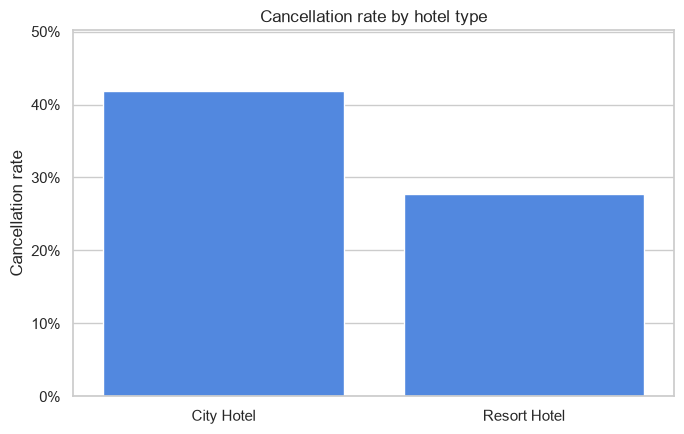

Observation: City Hotel has the higher recorded cancellation rate (41.8%) compared with Resort Hotel (27.8%). This difference is descriptive, not causal.


In [ ]:
# Visualization 1: cancellation rate by hotel type
hotel_summary = (
    clean.groupby("hotel", as_index=False)
    .agg(cancellation_rate=("is_canceled", "mean"), bookings=("is_canceled", "size"))
    .sort_values("cancellation_rate", ascending=False)
)
display(hotel_summary.style.format({"cancellation_rate": "{:.1%}", "bookings": "{:,}"}))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=hotel_summary, x="hotel", y="cancellation_rate", color="#3B82F6", ax=ax)
ax.set(title="Cancellation rate by hotel type", xlabel="", ylabel="Cancellation rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylim(0, min(1, hotel_summary["cancellation_rate"].max() * 1.2))
plt.tight_layout()
plt.show()

high = hotel_summary.iloc[0]
low = hotel_summary.iloc[-1]
print(
    f"Observation: {high['hotel']} has the higher recorded cancellation rate "
    f"({high['cancellation_rate']:.1%}) compared with {low['hotel']} "
    f"({low['cancellation_rate']:.1%}). This difference is descriptive, not causal."
)


,lead_time_band,cancellation_rate,bookings
0,"(-0.001, 18.0]",14.6%,"30,138"
1,"(18.0, 69.0]",35.9%,"29,615"
2,"(69.0, 161.0]",42.7%,"29,882"
3,"(161.0, 737.0]",55.4%,"29,575"


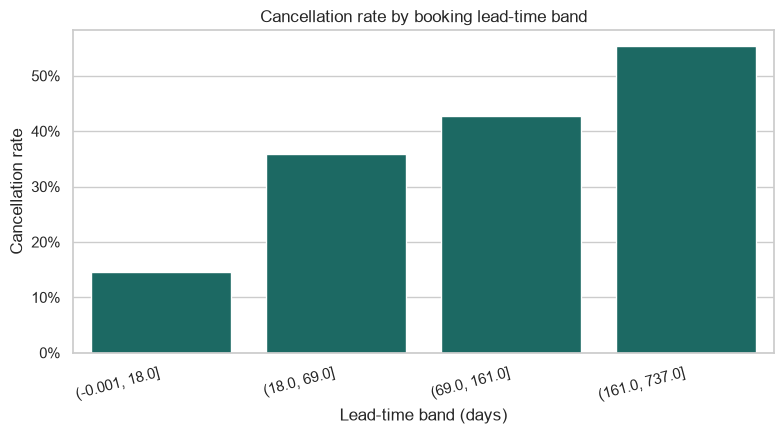

Observation: the longest lead-time band has a 55.4% cancellation rate; the shortest band has 14.6%. Longer lead time gives more opportunity for plans to change, but this chart alone does not establish why.


In [ ]:
# Visualization 2: cancellation rate across lead-time quartiles
lead_frame = clean[["lead_time", "is_canceled"]].copy()
lead_frame["lead_time_band"] = pd.qcut(lead_frame["lead_time"], q=4, duplicates="drop")
lead_summary = (
    lead_frame.groupby("lead_time_band", observed=False)
    .agg(cancellation_rate=("is_canceled", "mean"), bookings=("is_canceled", "size"))
    .reset_index()
)
lead_summary["lead_time_band"] = lead_summary["lead_time_band"].astype(str)
display(lead_summary.style.format({"cancellation_rate": "{:.1%}", "bookings": "{:,}"}))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=lead_summary, x="lead_time_band", y="cancellation_rate", color="#0F766E", ax=ax)
ax.set(title="Cancellation rate by booking lead-time band", xlabel="Lead-time band (days)", ylabel="Cancellation rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

short_band = lead_summary.iloc[0]
long_band = lead_summary.iloc[-1]
print(
    f"Observation: the longest lead-time band has a {long_band['cancellation_rate']:.1%} "
    f"cancellation rate; the shortest band has {short_band['cancellation_rate']:.1%}. "
    "Longer lead time gives more opportunity for plans to change, but this chart alone does not establish why."
)


,market_segment,cancellation_rate,bookings
1,Complementary,12.2%,728
3,Direct,15.4%,"12,582"
2,Corporate,18.8%,"5,282"
5,Offline TA/TO,34.3%,"24,182"
6,Online TA,36.8%,"56,408"
4,Groups,61.1%,"19,791"


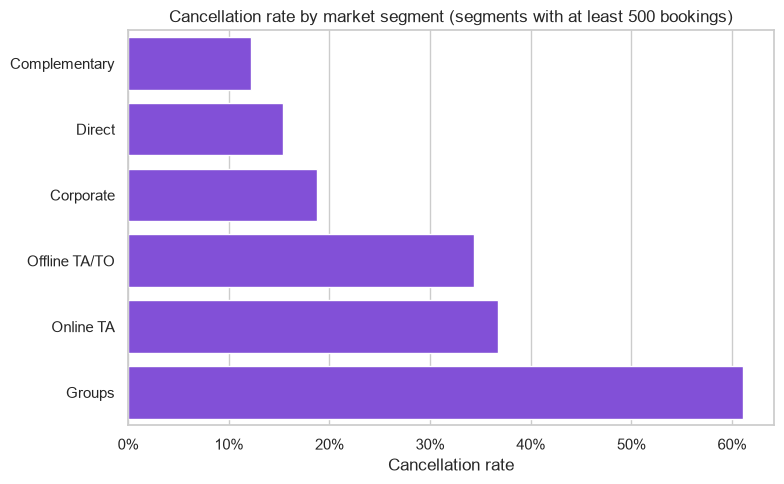

Observation: among segments with at least 500 bookings, Groups has the highest rate (61.1%) and Complementary the lowest (12.2%).


In [ ]:
# Visualization 3: cancellation rate by market segment
segment_summary = (
    clean.groupby("market_segment", as_index=False)
    .agg(cancellation_rate=("is_canceled", "mean"), bookings=("is_canceled", "size"))
)
segment_summary = segment_summary.loc[segment_summary["bookings"] >= 500].sort_values("cancellation_rate")
display(segment_summary.style.format({"cancellation_rate": "{:.1%}", "bookings": "{:,}"}))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=segment_summary, y="market_segment", x="cancellation_rate", color="#7C3AED", ax=ax)
ax.set(title="Cancellation rate by market segment (segments with at least 500 bookings)", xlabel="Cancellation rate", ylabel="")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

low_segment = segment_summary.iloc[0]
high_segment = segment_summary.iloc[-1]
print(
    f"Observation: among segments with at least 500 bookings, {high_segment['market_segment']} "
    f"has the highest rate ({high_segment['cancellation_rate']:.1%}) and "
    f"{low_segment['market_segment']} the lowest ({low_segment['cancellation_rate']:.1%})."
)


,cancellation_rate,bookings
arrival_date_month,,
January,30.5%,"5,921"
February,33.4%,"8,052"
March,32.2%,"9,768"
April,40.8%,"11,078"
May,39.7%,"11,780"
June,41.5%,"10,929"
July,37.5%,"12,644"
August,37.8%,"13,861"
September,39.2%,"10,500"


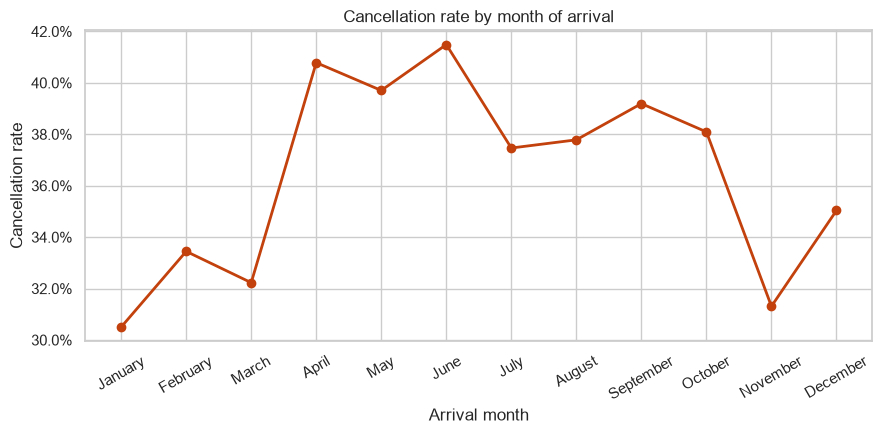

Observation: the pooled data has its highest cancellation rate in June (41.5%) and lowest in January (30.5%). The chart pools only the years represented in this dataset.


In [ ]:
# Visualization 4: cancellation rate by month of arrival
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
month_summary = (
    clean.groupby("arrival_date_month")
    .agg(cancellation_rate=("is_canceled", "mean"), bookings=("is_canceled", "size"))
    .reindex(month_order)
    .dropna()
)
display(month_summary.style.format({"cancellation_rate": "{:.1%}", "bookings": "{:,}"}))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(month_summary.index, month_summary["cancellation_rate"], marker="o", linewidth=2, color="#C2410C")
ax.set(title="Cancellation rate by month of arrival", xlabel="Arrival month", ylabel="Cancellation rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

highest_month = month_summary["cancellation_rate"].idxmax()
lowest_month = month_summary["cancellation_rate"].idxmin()
print(
    f"Observation: the pooled data has its highest cancellation rate in {highest_month} "
    f"({month_summary.loc[highest_month, 'cancellation_rate']:.1%}) and lowest in "
    f"{lowest_month} ({month_summary.loc[lowest_month, 'cancellation_rate']:.1%}). "
    "The chart pools only the years represented in this dataset."
)


## 5. Modeling approach

This is a binary classification task. The chronological holdout uses the latest 20% of arrival dates as test data, so the model is evaluated on later arrivals than it saw during training. Arrival year is used only to form the split and is not given to the classifier.

Gradient boosting builds a sequence of small decision trees, with each tree trying to improve on earlier errors. It is suitable here because booking data contains non-linear patterns and a mix of numeric and categorical features. One-hot encoding makes the selected categories usable by the model.

The probability threshold is selected by maximizing F1 on a validation slice from the training period. The later test period is not used to choose the threshold. The positive class is cancellation. Precision answers how many flagged bookings were actually canceled; recall answers how many cancellations were found; F1 balances those two. ROC-AUC and average precision summarize ranking quality across thresholds. The notebook also reports the default 0.50 threshold for comparison. Accuracy is included but should not be read alone because the classes are uneven.


In [ ]:
numeric_features = [
    "lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
    "babies", "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled",
]
categorical_features = [
    "hotel", "arrival_date_month", "meal", "market_segment",
    "distribution_channel", "reserved_room_type", "deposit_type", "customer_type",
]
feature_columns = numeric_features + categorical_features

# Reserve the latest 20% of arrivals for the final, untouched test period.
test_cutoff = clean["arrival_date"].quantile(0.80)
train_mask = clean["arrival_date"] < test_cutoff
test_mask = ~train_mask
train_frame = clean.loc[train_mask].copy()
test_frame = clean.loc[test_mask].copy()

# Use the latest 20% of the training period for threshold selection.
validation_cutoff = train_frame["arrival_date"].quantile(0.80)
fit_frame = train_frame.loc[train_frame["arrival_date"] < validation_cutoff].copy()
validation_frame = train_frame.loc[train_frame["arrival_date"] >= validation_cutoff].copy()

X_fit = fit_frame[feature_columns]
y_fit = fit_frame["is_canceled"]
X_validation = validation_frame[feature_columns]
y_validation = validation_frame["is_canceled"]
X_train = train_frame[feature_columns]
y_train = train_frame["is_canceled"]
X_test = test_frame[feature_columns]
y_test = test_frame["is_canceled"]

print(f"Threshold-selection validation period: {validation_frame['arrival_date'].min().date()} to {validation_frame['arrival_date'].max().date()}")
print(f"Final test period: {test_frame['arrival_date'].min().date()} to {test_frame['arrival_date'].max().date()}")
print(f"Model-fit rows before validation: {len(X_fit):,}")
print(f"Full training rows after threshold selection: {len(X_train):,}")
print(f"Final test bookings: {len(X_test):,}")
print(f"Cancellation share in training: {y_train.mean():.1%}")
print(f"Cancellation share in test: {y_test.mean():.1%}")

def make_model():
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

    numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder),
    ])
    preprocessor = ColumnTransformer(
        [
            ("numeric", numeric_pipeline, numeric_features),
            ("categorical", categorical_pipeline, categorical_features),
        ],
        sparse_threshold=0.0,
    )
    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=100, learning_rate=0.08, max_depth=2,
            min_samples_leaf=20, subsample=0.8, random_state=42,
        )),
    ])

# Choose the decision threshold using only the validation period.
validation_model = make_model()
validation_model.fit(X_fit, y_fit)
validation_probability = validation_model.predict_proba(X_validation)[:, 1]
validation_precision, validation_recall, candidate_thresholds = precision_recall_curve(
    y_validation, validation_probability
)
validation_f1 = (
    2 * validation_precision[:-1] * validation_recall[:-1]
    / np.maximum(validation_precision[:-1] + validation_recall[:-1], 1e-12)
)
best_threshold_index = int(np.argmax(validation_f1))
selected_threshold = float(candidate_thresholds[best_threshold_index])
print(f"Selected threshold from validation F1: {selected_threshold:.3f}")
print(f"Best validation F1 at that threshold: {validation_f1[best_threshold_index]:.3f}")

# Refit with all training-period rows, then evaluate once on the later test period.
model = make_model()
model.fit(X_train, y_train)
y_probability = model.predict_proba(X_test)[:, 1]
y_pred_default = (y_probability >= 0.50).astype(int)
y_pred = (y_probability >= selected_threshold).astype(int)

majority_label = int(y_train.mode().iloc[0])
baseline_prediction = np.full(len(y_test), majority_label, dtype=int)
baseline_probability = np.full(len(y_test), float(y_train.mean()))

def summarize_metrics(name, actual, predicted, probability, threshold=None):
    return {
        "model": name,
        "threshold": threshold,
        "accuracy": accuracy_score(actual, predicted),
        "precision_cancelled": precision_score(actual, predicted, zero_division=0),
        "recall_cancelled": recall_score(actual, predicted, zero_division=0),
        "f1_cancelled": f1_score(actual, predicted, zero_division=0),
        "roc_auc": roc_auc_score(actual, probability),
        "average_precision": average_precision_score(actual, probability),
    }

metrics = pd.DataFrame([
    summarize_metrics("Majority-class baseline", y_test, baseline_prediction, baseline_probability, None),
    summarize_metrics("Gradient boosting at 0.50", y_test, y_pred_default, y_probability, 0.50),
    summarize_metrics("Gradient boosting, validation-tuned", y_test, y_pred, y_probability, selected_threshold),
])
display(metrics.style.format({
    "threshold": "{:.3f}", "accuracy": "{:.3f}", "precision_cancelled": "{:.3f}",
    "recall_cancelled": "{:.3f}", "f1_cancelled": "{:.3f}",
    "roc_auc": "{:.3f}", "average_precision": "{:.3f}",
}))


Threshold-selection validation period: 2016-12-10 to 2017-04-21
Final test period: 2017-04-22 to 2017-08-31
Model-fit rows before validation: 76,098
Full training rows after threshold selection: 95,192
Final test bookings: 24,018
Cancellation share in training: 36.1%
Cancellation share in test: 41.0%


Selected threshold from validation F1: 0.334
Best validation F1 at that threshold: 0.668


,model,threshold,accuracy,precision_cancelled,recall_cancelled,f1_cancelled,roc_auc,average_precision
0,Majority-class baseline,nan,0.590,0.000,0.000,0.000,0.500,0.410
1,Gradient boosting at 0.50,0.500,0.689,0.988,0.245,0.392,0.775,0.732
2,"Gradient boosting, validation-tuned",0.334,0.678,0.578,0.795,0.669,0.775,0.732


Classification report at validation-selected threshold 0.334 (cancellation is the positive class):
              precision    recall  f1-score   support

not canceled       0.81      0.60      0.69     14174
    canceled       0.58      0.80      0.67      9844

    accuracy                           0.68     24018
   macro avg       0.69      0.70      0.68     24018
weighted avg       0.71      0.68      0.68     24018



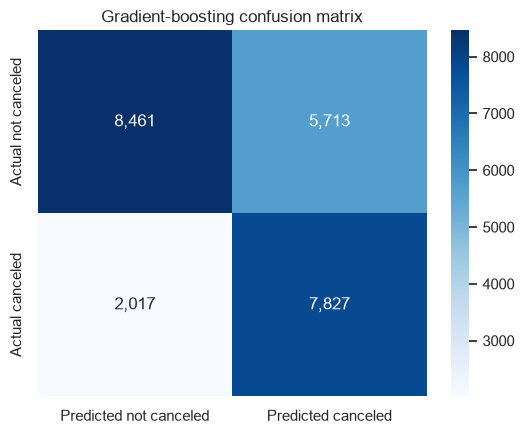

Plain-language result: on the later-arrival holdout, the model found 79.5% of cancellations (recall). Of the bookings it flagged, 57.8% were canceled (precision). Its cancellation F1 is 0.669; compare this with the majority-class baseline above.


In [ ]:
print(f"Classification report at validation-selected threshold {selected_threshold:.3f} (cancellation is the positive class):")
print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=["not canceled", "canceled"], zero_division=0,
))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    cm, annot=True, fmt=",", cmap="Blues",
    xticklabels=["Predicted not canceled", "Predicted canceled"],
    yticklabels=["Actual not canceled", "Actual canceled"], ax=ax,
)
ax.set(title="Gradient-boosting confusion matrix", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

boost = metrics.loc[metrics["model"] == "Gradient boosting, validation-tuned"].iloc[0]
print(
    f"Plain-language result: on the later-arrival holdout, the model found "
    f"{boost['recall_cancelled']:.1%} of cancellations (recall). Of the bookings it flagged, "
    f"{boost['precision_cancelled']:.1%} were canceled (precision). Its cancellation F1 is "
    f"{boost['f1_cancelled']:.3f}; compare this with the majority-class baseline above."
)


## 6. What influenced the model?

The plot ranks one-hot encoded features by the fitted model's impurity-based feature importance. These scores describe how the trees used each feature to reduce prediction error. They are not causal effects, and category levels from the same field appear separately.


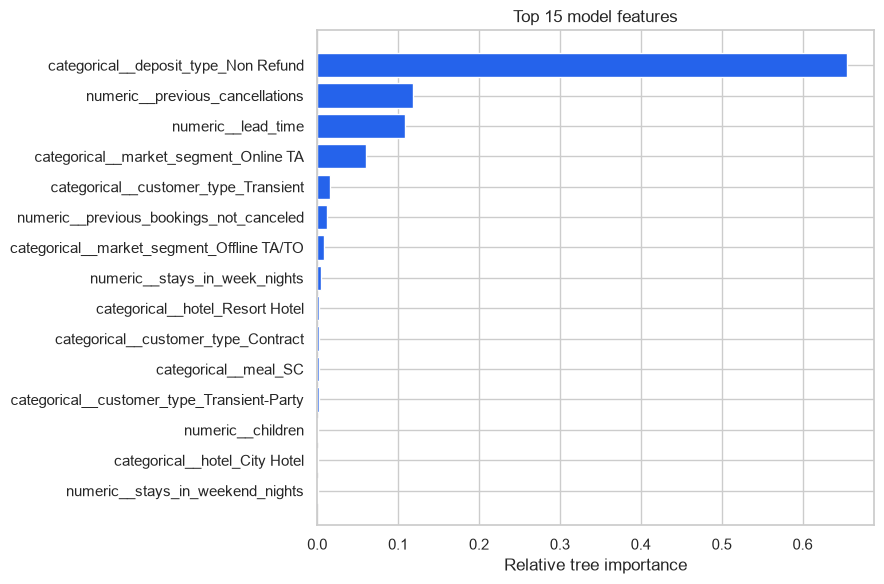

,feature,importance
0,categorical__deposit_type_Non Refund,0.6556
1,numeric__previous_cancellations,0.1187
2,numeric__lead_time,0.1091
3,categorical__market_segment_Online TA,0.0605
4,categorical__customer_type_Transient,0.0153
5,numeric__previous_bookings_not_canceled,0.0123
6,categorical__market_segment_Offline TA/TO,0.0090
7,numeric__stays_in_week_nights,0.0049
8,categorical__hotel_Resort Hotel,0.0022
9,categorical__customer_type_Contract,0.0020


Interpretation: the top-ranked fields were useful to this model on this dataset. Their importance does not prove that changing a field would change cancellation behavior.


In [ ]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importance = pd.DataFrame({
    "feature": feature_names,
    "importance": model.named_steps["classifier"].feature_importances_,
}).sort_values("importance", ascending=False)
top_importance = importance.head(15).sort_values("importance")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_importance["feature"], top_importance["importance"], color="#2563EB")
ax.set(title="Top 15 model features", xlabel="Relative tree importance", ylabel="")
plt.tight_layout()
plt.show()
display(importance.head(10).reset_index(drop=True).style.format({"importance": "{:.4f}"}))
print(
    "Interpretation: the top-ranked fields were useful to this model on this dataset. "
    "Their importance does not prove that changing a field would change cancellation behavior."
)


## 7. Conclusion, limitations, and next steps

Use the holdout metrics and charts above to state the result in your own words. Include the strongest pattern you observed, how boosting compared with the baseline, and what precision and recall mean. The printed draft below is a starting point; rewrite it so you can explain each claim in your presentation.


In [ ]:
top_feature = importance.iloc[0]["feature"]
draft_conclusion = (
    f"Draft to personalize: The later-arrival holdout contained {len(y_test):,} bookings, "
    f"with a cancellation rate of {y_test.mean():.1%}. Gradient boosting achieved an F1 of "
    f"{boost['f1_cancelled']:.3f}, recall of {boost['recall_cancelled']:.1%}, and precision "
    f"of {boost['precision_cancelled']:.1%} for cancellations, compared with the "
    f"majority-class baseline. The model relied most on {top_feature}. These results show "
    "that booking records contain useful cancellation patterns, but they do not establish causes."
)
print(draft_conclusion)
print("\nLimitations and next steps:")
print("- The data covers a limited historical period and two anonymous hotels.")
print("- The large exact-repeat count cannot be resolved without a booking identifier.")
print("- Some fields may not be available at the exact operational prediction time.")
print("- The threshold was selected for validation F1, which may not match the hotel's costs for false alerts and missed cancellations.")
print("- Future work could compare another boosting method, tune the threshold on a validation period, and test on newer independent data.")


Draft to personalize: The later-arrival holdout contained 24,018 bookings, with a cancellation rate of 41.0%. Gradient boosting achieved an F1 of 0.669, recall of 79.5%, and precision of 57.8% for cancellations, compared with the majority-class baseline. The model relied most on categorical__deposit_type_Non Refund. These results show that booking records contain useful cancellation patterns, but they do not establish causes.

Limitations and next steps:
- The data covers a limited historical period and two anonymous hotels.
- The large exact-repeat count cannot be resolved without a booking identifier.
- Some fields may not be available at the exact operational prediction time.
- The threshold was selected for validation F1, which may not match the hotel's costs for false alerts and missed cancellations.
- Future work could compare another boosting method, tune the threshold on a validation period, and test on newer independent data.


## 8. Reproducibility and submission

For Kaggle, upload this notebook, attach the Hotel Booking Demand dataset as an input, and run every cell from top to bottom. For local use, place hotel_bookings.csv in the data folder and install the packages listed in requirements.txt.

Before submission, replace the student and course placeholders, run all cells, read the generated charts and metrics, and personalize the conclusion in your own words. Keep the README with the project files as the short project report and presentation guide.
